In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, ConfusionMatrixDisplay
)

pd.set_option("display.max_columns", None)

In [2]:
data = pd.read_csv("titanic.csv")

print("Dimensions :", data.shape)
display(data.head())

print("\nTypes et valeurs non nulles :")
data.info()

print("\nValeurs manquantes :")
display(data.isnull().sum().to_frame("Valeurs manquantes"))

print("\nStatistiques descriptives :")
display(data.describe(include="all").T)

Dimensions : (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



Types et valeurs non nulles :
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB

Valeurs manquantes :


,Valeurs manquantes
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0



Statistiques descriptives :


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


Effectifs (0 = non survivant, 1 = survivant) :


,Nombre
Survived,
0,549
1,342


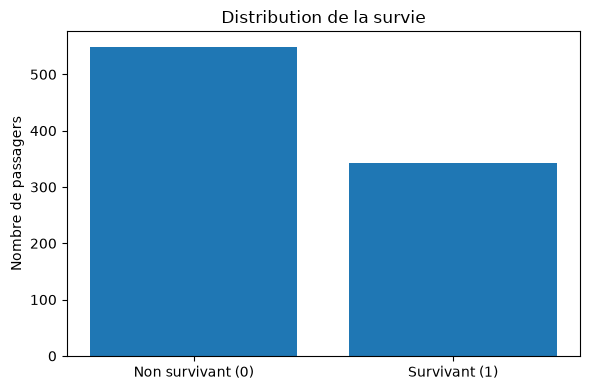

Taux de survie : 38.38 %


In [3]:
# Distribution de la variable cible
counts = data["Survived"].value_counts().sort_index()
print("Effectifs (0 = non survivant, 1 = survivant) :")
display(counts.to_frame("Nombre"))

plt.figure(figsize=(6, 4))
plt.bar(["Non survivant (0)", "Survivant (1)"], [counts.get(0, 0), counts.get(1, 0)])
plt.title("Distribution de la survie")
plt.ylabel("Nombre de passagers")
plt.tight_layout()
plt.show()

print("Taux de survie :", round(data["Survived"].mean() * 100, 2), "%")

In [4]:
features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
target = "Survived"

X = data[features].copy()
y = data[target].copy()

numeric_features = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
categorical_features = ["Sex", "Embarked"]

print("Variables explicatives :", features)
print("Valeurs manquantes dans X :")
display(X.isnull().sum().to_frame("Valeurs manquantes"))

Variables explicatives : ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
Valeurs manquantes dans X :


,Valeurs manquantes
Pclass,0
Sex,0
Age,177
SibSp,0
Parch,0
Fare,0
Embarked,2


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Entraînement :", X_train.shape)
print("Test :", X_test.shape)
print("\nProportion de survivants — entraînement :", round(y_train.mean(), 3))
print("Proportion de survivants — test :", round(y_test.mean(), 3))

Entraînement : (712, 7)
Test : (179, 7)

Proportion de survivants — entraînement : 0.383
Proportion de survivants — test : 0.385


In [6]:
numeric_preprocessor_log = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_log = ColumnTransformer(transformers=[
    ("num", numeric_preprocessor_log, numeric_features),
    ("cat", categorical_preprocessor, categorical_features)
])

numeric_preprocessor_rf = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

preprocessor_rf = ColumnTransformer(transformers=[
    ("num", numeric_preprocessor_rf, numeric_features),
    ("cat", categorical_preprocessor, categorical_features)
])

In [7]:
log_model = Pipeline(steps=[
    ("preprocessing", preprocessor_log),
    ("classifier", LogisticRegression(max_iter=2000, random_state=42))
])

rf_model = Pipeline(steps=[
    ("preprocessing", preprocessor_rf),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight=None
    ))
])

log_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

print("Les deux modèles ont été entraînés.")

Les deux modèles ont été entraînés.


In [8]:
models = {
    "Régression logistique": log_model,
    "Random Forest": rf_model
}

results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    y_prob = model.predict_proba(X_test)[:, 1]
    results.append({
        "Modèle": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (survie)": precision_score(y_test, y_pred, zero_division=0),
        "Recall (survie)": recall_score(y_test, y_pred, zero_division=0),
        "F1-score (survie)": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).set_index("Modèle")
display(results_df.round(3))

,Accuracy,Precision (survie),Recall (survie),F1-score (survie),ROC-AUC
Modèle,,,,,
Régression logistique,0.804,0.793,0.667,0.724,0.844
Random Forest,0.821,0.814,0.696,0.750,0.832


In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

cv_rows = []
for name, model in models.items():
    scores = cross_validate(
        model, X_train, y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )
    cv_rows.append({
        "Modèle": name,
        "Accuracy moyenne CV": scores["test_accuracy"].mean(),
        "Écart-type accuracy": scores["test_accuracy"].std(),
        "F1 moyen CV": scores["test_f1"].mean(),
        "Recall moyen CV": scores["test_recall"].mean()
    })

cv_results = pd.DataFrame(cv_rows).set_index("Modèle")
display(cv_results.round(3))

,Accuracy moyenne CV,Écart-type accuracy,F1 moyen CV,Recall moyen CV
Modèle,,,,
Régression logistique,0.796,0.028,0.726,0.703
Random Forest,0.803,0.019,0.741,0.732


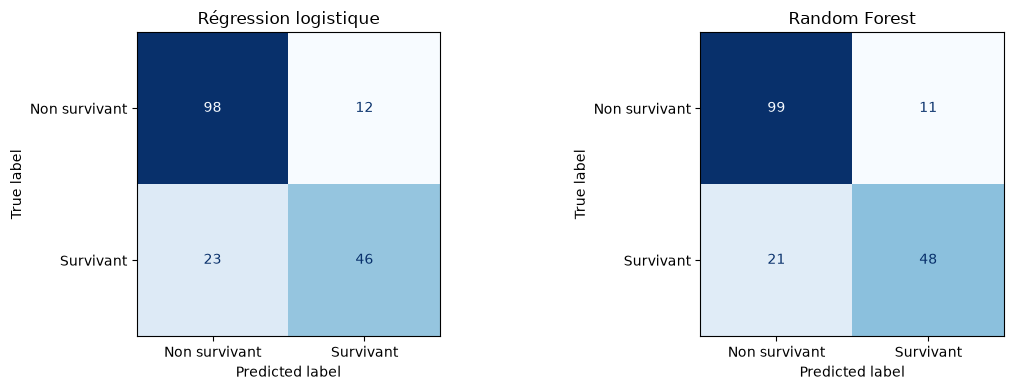

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions[name],
        display_labels=["Non survivant", "Survivant"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

In [11]:
for name, y_pred in predictions.items():
    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)
    print(classification_report(
        y_test, y_pred,
        labels=[0, 1],
        target_names=["Non survivant", "Survivant"],
        zero_division=0
    ))


Régression logistique
               precision    recall  f1-score   support

Non survivant       0.81      0.89      0.85       110
    Survivant       0.79      0.67      0.72        69

     accuracy                           0.80       179
    macro avg       0.80      0.78      0.79       179
 weighted avg       0.80      0.80      0.80       179


Random Forest
               precision    recall  f1-score   support

Non survivant       0.82      0.90      0.86       110
    Survivant       0.81      0.70      0.75        69

     accuracy                           0.82       179
    macro avg       0.82      0.80      0.81       179
 weighted avg       0.82      0.82      0.82       179



,Variable,Importance
4,num__Fare,0.257490
1,num__Age,0.243869
6,cat__Sex_male,0.153717
5,cat__Sex_female,0.136457
0,num__Pclass,0.087248
2,num__SibSp,0.046531
3,num__Parch,0.038527
9,cat__Embarked_S,0.016330
7,cat__Embarked_C,0.012098
8,cat__Embarked_Q,0.007733


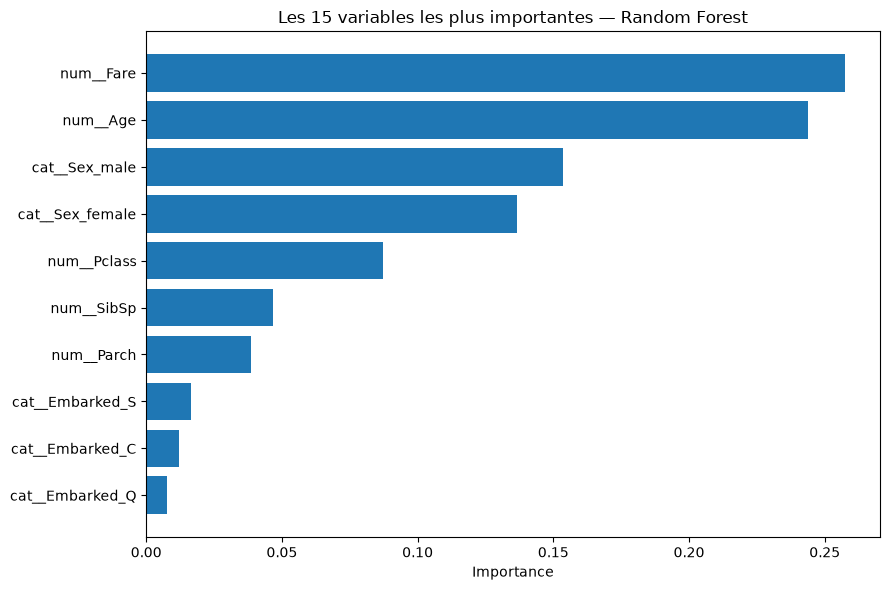

In [12]:
# Extraire les noms des variables après pretraitement
fitted_preprocessor = rf_model.named_steps["preprocessing"]
feature_names = fitted_preprocessor.get_feature_names_out()
importances = rf_model.named_steps["classifier"].feature_importances_

importance_df = pd.DataFrame({
    "Variable": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

display(importance_df.head(15))

top = importance_df.head(15).sort_values("Importance")
plt.figure(figsize=(9, 6))
plt.barh(top["Variable"], top["Importance"])
plt.title("Les 15 variables les plus importantes — Random Forest")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [13]:
# Modèle classé ici selon le F1-score de la classe positive (survie).
best_f1_name = results_df["F1-score (survie)"].idxmax()
best_accuracy_name = results_df["Accuracy"].idxmax()
best_recall_name = results_df["Recall (survie)"].idxmax()

print(f"Meilleur F1-score pour la classe Survivant : {best_f1_name} "
      f"({results_df.loc[best_f1_name, 'F1-score (survie)']:.3f})")
print(f"Meilleure accuracy sur le test : {best_accuracy_name} "
      f"({results_df.loc[best_accuracy_name, 'Accuracy']:.3f})")
print(f"Meilleur rappel des survivants : {best_recall_name} "
      f"({results_df.loc[best_recall_name, 'Recall (survie)']:.3f})")

print("\nInterprétation :")
print("Le modèle à retenir dépend de la priorité. Le F1-score équilibre précision et rappel ; "
      "le rappel est important si l'on veut éviter de manquer des survivants.")
print("Vérifiez également la validation croisée : un score moyen plus élevé et un écart-type "
      "plus faible peuvent indiquer une meilleure stabilité.")
print("\nLimites : dataset de taille limitée, variables choisies selon le TP, "
      "résultats sensibles au découpage et aucune garantie de généralisation à d'autres populations.")

CONCLUSION — À discuter dans le compte rendu
-------------------------------------------------------
Meilleur F1-score pour la classe Survivant : Random Forest (0.750)
Meilleure accuracy sur le test : Random Forest (0.821)
Meilleur rappel des survivants : Random Forest (0.696)

Interprétation :
Le modèle à retenir dépend de la priorité. Le F1-score équilibre précision et rappel ; le rappel est important si l'on veut éviter de manquer des survivants.
Vérifiez également la validation croisée : un score moyen plus élevé et un écart-type plus faible peuvent indiquer une meilleure stabilité.

Limites : dataset de taille limitée, variables choisies selon le TP, résultats sensibles au découpage et aucune garantie de généralisation à d'autres populations.
